# Rossmann sales: explore the data

Daily sales for 1,115 Rossmann drugstores across Germany, January 2013 to July 2015, plus store details
(type, assortment, nearest competitor, ongoing promotions). The goal of the project: forecast the next 6
weeks of sales and customer traffic for every store, then turn the forecast into a cost-minimizing
staffing plan.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
IMAGES = ROOT / "images"
PROCESSED.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(exist_ok=True)

train = pd.read_csv(RAW / "train.csv", parse_dates=["Date"], dtype={"StateHoliday": str})
future = pd.read_csv(RAW / "test.csv", parse_dates=["Date"], dtype={"StateHoliday": str})
stores = pd.read_csv(RAW / "store.csv")

print("history:", train.shape, train["Date"].min().date(), "to", train["Date"].max().date())
print("future calendar:", future.shape, future["Date"].min().date(), "to", future["Date"].max().date())
print("stores:", stores.shape)
train.head()

history: (1017209, 9) 2013-01-01 to 2015-07-31
future calendar: (41088, 8) 2015-08-01 to 2015-09-17
stores: (1115, 10)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


`test.csv` is Kaggle's competition period: it has no sales, but it does have the promotion and holiday
calendar for 856 stores from August 1 to September 17, 2015. That is exactly what a planner would know in
advance, so it becomes the window to forecast.

In [2]:
days_per_store = train.groupby("Store")["Date"].nunique()
print(days_per_store.value_counts().rename("stores"))

gap_stores = days_per_store[days_per_store < 900].index
missing = pd.date_range("2013-01-01", "2015-07-31").difference(train.loc[train["Store"] == gap_stores[0], "Date"])
print(f"{len(gap_stores)} stores are missing {len(missing)} days: {missing.min().date()} to {missing.max().date()}")

Date
942    934
758    180
941      1
Name: stores, dtype: int64
180 stores are missing 184 days: 2014-07-01 to 2014-12-31


In [3]:
print("Closed days:", (train["Open"] == 0).sum())
print("Open days with zero sales:", ((train["Open"] == 1) & (train["Sales"] == 0)).sum())
print("Share of stores open on Sundays:", round(train.loc[train["DayOfWeek"] == 7, "Open"].mean(), 3))

opened = train[(train["Open"] == 1) & (train["Sales"] > 0)].copy()
print(f"Open days kept for modeling: {len(opened):,}")
print(f"Average day: {opened['Sales'].mean():,.0f} EUR in sales, {opened['Customers'].mean():,.0f} customers, "
      f"{opened['Sales'].sum() / opened['Customers'].sum():.2f} EUR per customer")

Closed days: 172817
Open days with zero sales: 54
Share of stores open on Sundays: 0.025


Open days kept for modeling: 844,338
Average day: 6,956 EUR in sales, 763 customers, 9.12 EUR per customer


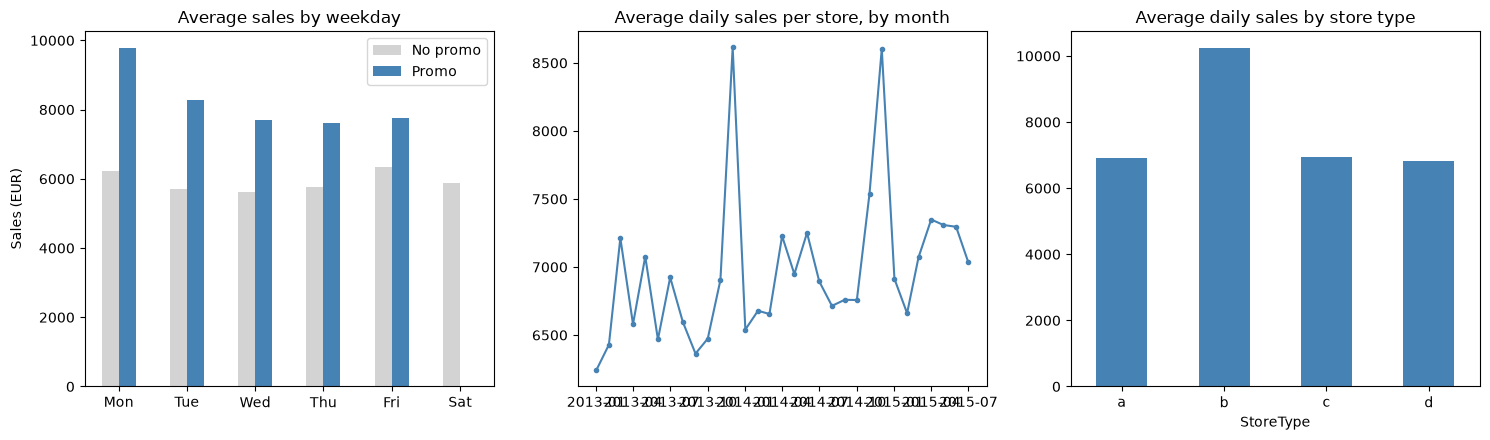

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

weekday = opened[opened["DayOfWeek"] < 7].groupby(["DayOfWeek", "Promo"])["Sales"].mean().unstack()
weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
weekday.columns = ["No promo", "Promo"]
weekday.plot(kind="bar", ax=axes[0], color=["lightgray", "steelblue"], rot=0)
axes[0].set_title("Average sales by weekday")
axes[0].set_ylabel("Sales (EUR)")

monthly = opened.set_index("Date").resample("MS")["Sales"].mean()
axes[1].plot(monthly.index, monthly.values, color="steelblue", marker="o", markersize=3)
axes[1].set_title("Average daily sales per store, by month")

by_type = opened.merge(stores[["Store", "StoreType"]], on="Store").groupby("StoreType")[["Sales", "Customers"]].mean()
by_type["Sales"].plot(kind="bar", ax=axes[2], color="steelblue", rot=0)
axes[2].set_title("Average daily sales by store type")

plt.tight_layout()
plt.savefig(IMAGES / "sales_patterns.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
promo = opened.groupby("Promo")[["Sales", "Customers"]].mean()
promo["sales_per_customer"] = promo["Sales"] / promo["Customers"]
promo.loc["lift"] = promo.loc[1] / promo.loc[0] - 1
promo.round(3)

,Sales,Customers,sales_per_customer
Promo,,,
0,5929.826,696.906,8.509
1,8228.740,844.481,9.744
lift,0.388,0.212,0.145


In [6]:
holidays = opened.groupby("StateHoliday")["Sales"].agg(["size", "mean"]).round(0)
school = opened.groupby("SchoolHoliday")["Sales"].mean().round(0)
december = opened[opened["Date"].dt.month == 12].groupby(opened["Date"].dt.day)["Sales"].mean()
print(holidays)
print("\nSchool holiday vs. not:", school.to_dict())
print("\nDecember peak day average:", round(december.max()), "vs. December average", round(december.mean()))

                size    mean
StateHoliday                
0             843428  6954.0
a                694  8487.0
b                145  9888.0
c                 71  9744.0

School holiday vs. not: {0: 6897.0, 1: 7201.0}

December peak day average: 12970 vs. December average 8730


In [7]:
opened.to_parquet(PROCESSED / "sales_open_days.parquet", index=False)
train.to_parquet(PROCESSED / "train_all_days.parquet", index=False)
future.to_parquet(PROCESSED / "future_calendar.parquet", index=False)
stores.to_parquet(PROCESSED / "stores.parquet", index=False)
print("Saved processed data")

Saved processed data


### Findings
- **1,017,209 daily records for 1,115 stores.** Most stores have all 942 days, but 180 stores are missing
  July to December 2014 (184 days). The model trains on the days that exist rather than inventing them.
- **Stores are closed on Sundays:** only 2.5% of store-Sundays are open. Closed days (172,817) and 54 open
  days with zero sales are left out of modeling, since there is nothing to forecast on them.
- **An average open day:** 6,956 EUR in sales from 763 customers, about 9.12 EUR per customer.
- **Promotions are the biggest lever:** +39% sales, driven by 21% more customers who also spend 15% more each.
- Mondays are the busiest weekday, December peaks at about 13,000 EUR on the busiest days (vs. 8,700 on an
  average December day), and the 17 "type b" stores sell the most per day.
- The last 6 weeks of history become the test, and Kaggle's future calendar (Aug 1 to Sep 17, 2015)
  becomes the window to forecast.